<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%2011/MRayhanZamzami_JS11_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 2 - Klasifikasi SVM dengan Data Non-Linier (Kernel Trick)

Pemanfaatan kernel RBF untuk pemisahan data berbentuk lingkaran konsentris.

## Langkah 1 - Ilustrasi Data Non-Linier

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [2]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    ax.contour(X_grid, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, edgecolors='black', facecolors='none', label='Support Vectors')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

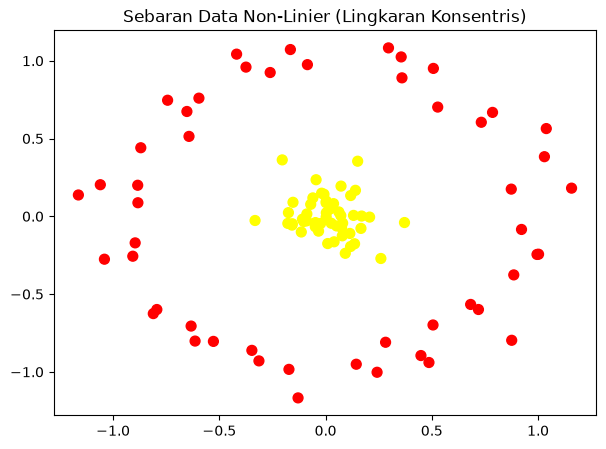

In [3]:
from sklearn.datasets import make_circles

# Buat data dummy berbentuk lingkaran konsentris (non-linier)
X, y = make_circles(100, factor=0.1, noise=0.1, random_state=42)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title('Sebaran Data Non-Linier (Lingkaran Konsentris)')
plt.show()

## Langkah 2 - Kegagalan SVM Linier pada Data Non-Linier

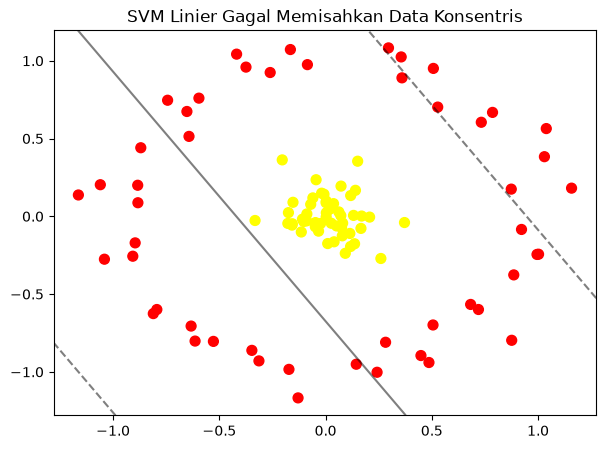

In [4]:
clf = SVC(kernel='linear').fit(X, y)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)
plt.title('SVM Linier Gagal Memisahkan Data Konsentris')
plt.show()

## Langkah 3 - Proyeksi ke Dimensi Lebih Tinggi (Basis Fungsi Radial)

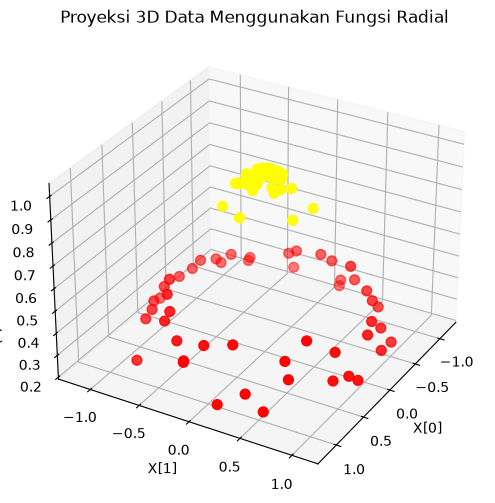

In [5]:
# Tambah dimensi z menggunakan radial basis function (RBF)
r = np.exp(-(X ** 2).sum(1))

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
ax.set_xlabel('X[0]')
ax.set_ylabel('X[1]')
ax.set_zlabel('r (Radial Basis)')
ax.view_init(elev=30, azim=30)
plt.title('Proyeksi 3D Data Menggunakan Fungsi Radial')
plt.show()

## Langkah 4 - SVM dengan Kernel RBF

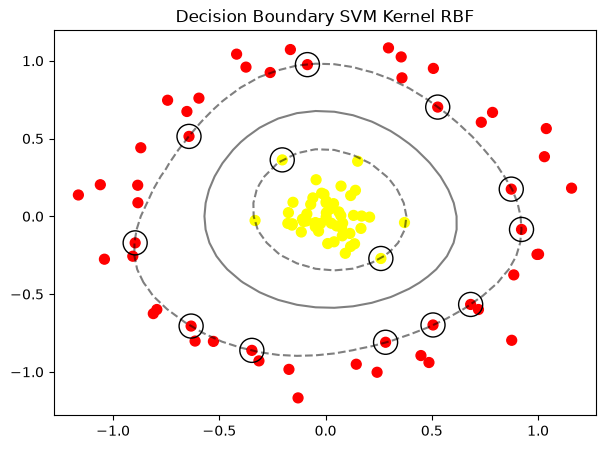

In [6]:
clf_rbf = SVC(kernel='rbf', C=1E6)
clf_rbf.fit(X, y)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf_rbf)
plt.title('Decision Boundary SVM Kernel RBF')
plt.show()